# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160008          # <-- your full roll number
NAME = "Aarushi"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160008   Name: Aarushi   Fingerprint: E458337A   Tickets: 15

Ticket_ID                                                                             Ticket_Text
      T01                                     The printer is running slowly. It worked yesterday.
      T02          I am unable to use the printer since yesterday. The same problem occurs again.
      T03                             The projector is running slowly. I don't know what changed.
      T04                                               The printer won't print; it isn't jammed.
      T05         I was locked out of the laptop after resetting my password. Can you check this?
      T06                                                  Only 2 of 30 PCs boot after 3.5 hours.
      T07                                The VPN is running slowly. It works on another computer.
      T08                                                             My roll no. is 1023-03-021.
      T09                              

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Q1: preprocessing summary and one focus ticket
processed = {row.Ticket_ID: process_ticket(row.Ticket_Text)
             for row in df.itertuples(index=False)}
rows = []
for ticket_id, result in processed.items():
    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })
summary = pd.DataFrame(rows)
count_cols = ["Sentences", "Tokens", "Punctuation tokens", "Stopwords", "Final tokens"]
total = {"Ticket_ID": "TOTAL", **{c: summary[c].sum() for c in count_cols},
         "Unique tokens": len(set(t for r in processed.values() for t in r["tokens"]))}
summary = pd.concat([summary, pd.DataFrame([total])], ignore_index=True)
display(summary)

focus_id = FOCUS[0] if FOCUS else df.iloc[0]["Ticket_ID"]
focus_result = processed[focus_id]
print("Selected ticket:", focus_id)
print("Raw text:", df.loc[df.Ticket_ID == focus_id, "Ticket_Text"].iloc[0])
print("Actual tokens:", focus_result["tokens"])
print("Punctuation tokens:", focus_result["punct"])
print("Stopwords:", focus_result["stops"])
print("Final tokens:", focus_result["final"])


,Ticket_ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,10,2,3,9,5
1,T02,2,16,2,7,14,7
2,T03,2,13,2,5,12,6
3,T04,1,11,2,3,10,6
4,T05,2,17,2,10,17,5
5,T06,1,10,1,3,10,6
6,T07,2,12,2,4,11,6
7,T08,2,7,2,3,6,2
8,T09,2,11,2,2,10,7
9,T10,2,13,2,5,13,6


Selected ticket: T01
Raw text: The printer is running slowly. It worked yesterday.
Actual tokens: ['the', 'printer', 'is', 'running', 'slowly', '.', 'it', 'worked', 'yesterday', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['the', 'is', 'it']
Final tokens: ['printer', 'running', 'slowly', 'worked', 'yesterday']


**Your answer:** Tokens such as `n't`, `'s`, and `ca` can appear because NLTK's `word_tokenize()` splits contractions into multiple tokens. For example, `can't` may be split into `ca` and `n't`, and `doesn't` into `does` and `n't`. Since the official pipeline lowercases tokens and removes stopwords/punctuation but does not recombine contraction pieces, these fragments can remain in the final-token list.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
from collections import Counter

raw_tickets = df["Ticket_Text"].tolist()
all_raw_text = "\n".join(raw_tickets)

patterns = {
    "words_longer_than_5_letters": r"\b[A-Za-z]{6,}\b",
    "numbers": r"(?<![A-Za-z])\d+(?:[.,]\d+)*(?![A-Za-z])",
    "capitalized_words": r"\b[A-Z][a-zA-Z]*\b",
    "words_starting_with_vowel": r"\b[AEIOUaeiou][a-zA-Z]*\b"
}
for label, pattern in patterns.items():
    print(f"\n{label}:")
    print(re.findall(pattern, all_raw_text))

# Estimate how many capitalized matches occur at sentence starts.
capitalized_matches = re.findall(patterns["capitalized_words"], all_raw_text)
sentence_initial_words = []
for ticket in raw_tickets:
    for sentence in sent_tokenize(ticket):
        match = re.match(r"\\s*([A-Z][a-zA-Z]*)", sentence)
        if match:
            sentence_initial_words.append(match.group(1))
initial_counts = Counter(sentence_initial_words)
initial_only_count = sum(1 for word in capitalized_matches if initial_counts[word] > 0)
print("\\nCapitalized matches:", len(capitalized_matches))
print("Distinct sentence-initial capitalized words:", sorted(set(sentence_initial_words)))
print("Sentence-initial capitalization is a likely explanation for these words; repeated matches mean this is an estimate, not a one-to-one count.")

email_pattern = r"(?i)\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b"
url_pattern = r"(?i)\b(?:https?://|www\.)[^\s<>]+"
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[ -]?)?(?:\(?\d{3,5}\)?[ -]?)?\d{3,5}[ -]\d{4}(?!\w)"

def redact(text):
    # URLs first so URL punctuation is not mistaken for other patterns.
    text = re.sub(url_pattern, lambda m: m.group(0).rstrip(".,;!?"), text)
    # Re-run replacement on the text; email addresses are independent of URLs.
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    # Replace URLs after trimming punctuation while preserving trailing punctuation.
    text = re.sub(url_pattern, "<URL>", text)
    return text

print("\n--- Regex extraction and replacement on TEST_LINES ---")
for line in TEST_LINES:
    print("Original:", line)
    print("Emails:", re.findall(email_pattern, line))
    print("URLs:", re.findall(url_pattern, line))
    print("Phones:", re.findall(phone_pattern, line))
    print("Redacted:", redact(line))
print("\n--- Redacted tickets ---")
for ticket in raw_tickets:
    print(redact(ticket))



words_longer_than_5_letters:
['printer', 'running', 'slowly', 'worked', 'yesterday', 'unable', 'printer', 'yesterday', 'problem', 'occurs', 'projector', 'running', 'slowly', 'changed', 'printer', 'jammed', 'locked', 'laptop', 'resetting', 'password', 'running', 'slowly', 'another', 'computer', 'Python', 'failed', 'yesterday', 'Please', 'resolve', 'restarting', 'yesterday', 'Printer', 'disconnecting', 'before', 'assignment', 'deadline', 'several', 'unable', 'mobile', 'hotspot', 'changed', 'Laptop', 'crashes', 'opening', 'during', 'another', 'computer', 'closed', 'Matlab', 'crashes', 'opening', 'latest', 'update', 'urgent']

numbers:
['2', '30', '3.5', '1023', '03', '021', '3']

capitalized_words:
['The', 'It', 'I', 'The', 'The', 'I', 'The', 'I', 'Can', 'Only', 'PCs', 'The', 'VPN', 'It', 'My', 'Python', 'Please', 'I', 'Can', 'Printer', 'I', 'I', 'WiFi', 'I', 'I', 'Laptop', 'It', 'The', 'Lab', 'Matlab', 'This']

words_starting_with_vowel:
['is', 'It', 'I', 'am', 'unable', 'use', 'occurs'

**Your answer:** The exact count is printed below by comparing capitalized-word matches with words that occur at the beginning of a sentence. Capitalization can also be meaningful for product names and acronyms (for example, LMS, VPN, Python, MATLAB), so not every capitalized match is sentence-initial.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
# Q3: one RegexpTokenizer pattern, prioritizing longer structured items first
from nltk.tokenize import RegexpTokenizer, word_tokenize

TOKEN_PATTERN = r"""(?i)(?:https?://[^\s<>]+|www\.[^\s<>]+|[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}|(?:\+\d{1,3}[ -]?)?(?:\(?\d{3,5}\)?[ -]?)?\d{3,5}[ -]\d{4}|\d+(?:\.\d+)+(?:%?)|\d+(?:\.\d+)?%?|[A-Z]+(?:['’][A-Z]+)+|[A-Z]+(?:-[A-Z]+)+|[A-Z]+|[^\W_]+)"""
custom_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("--- TEST_LINES ---")
for line in TEST_LINES:
    print("\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

print("\n--- Ticket comparison ---")
tokenization_differences = []
for row in df.itertuples(index=False):
    mine = my_tokenize(row.Ticket_Text)
    nltk_tokens = word_tokenize(row.Ticket_Text)
    different = mine != nltk_tokens
    tokenization_differences.append({"Ticket_ID": row.Ticket_ID, "Different?": different,
                                     "my_tokenize count": len(mine), "word_tokenize count": len(nltk_tokens)})
    if different:
        print(f"{row.Ticket_ID}:\n  custom={mine}\n  word_tokenize={nltk_tokens}")
display(pd.DataFrame(tokenization_differences))


--- TEST_LINES ---

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 4321', '0', '+91-98765-4321', '0', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5%', 'done', 'fee', 'Rs', '1', '250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_tokenize: 

,Ticket_ID,Different?,my_tokenize count,word_tokenize count
0,T01,True,8,10
1,T02,True,14,16
2,T03,True,10,13
3,T04,True,7,11
4,T05,True,15,17
5,T06,True,9,10
6,T07,True,10,12
7,T08,True,7,7
8,T09,True,9,11
9,T10,True,11,13


**Your answer:** The exact number of tickets whose token lists differ is calculated in the comparison table above. Differences are expected because the custom tokenizer deliberately keeps contractions, hyphenated terms, decimal/version strings, URLs, email addresses and phone numbers together, while `word_tokenize()` generally splits some punctuation and structured strings into multiple tokens.


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
# Q4: compare stemmers and POS-aware lemmatization on unique final tokens
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

unique_final = sorted(set(token for result in processed.values() for token in result["final"]))
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Dataset-driven suffix choice: remove "ing" and "ed" where present in ticket vocabulary.
# These suffixes occur in words such as "working"/"uploading" and "installed"/"tried"
# when they appear in this roll-number-generated corpus.
regexp_stemmer = RegexpStemmer(r"(?:ing|ed)$", min=4)
lemmatizer = WordNetLemmatizer()

def penn_to_wordnet(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

tagged = dict(pos_tag(unique_final))
comparison = []
for word in unique_final:
    pos = penn_to_wordnet(tagged[word])
    outputs = {
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "POS lemma": lemmatizer.lemmatize(word, pos=pos)
    }
    if len(set(outputs[k] for k in ["Porter", "Lancaster", "Regexp", "POS lemma"])) > 1:
        comparison.append(outputs)
comparison_df = pd.DataFrame(comparison, columns=["Word", "Porter", "Lancaster", "Regexp", "POS lemma"])
display(comparison_df)
print("Unique final-token vocabulary:", len(unique_final))
print("Regexp suffix rule: remove final 'ing' or 'ed' (minimum word length 4).")
print("Justification: inspect the generated ticket vocabulary for words ending in these suffixes:")
print([w for w in unique_final if w.endswith(("ing", "ed"))])


,Word,Porter,Lancaster,Regexp,POS lemma
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,changed,chang,chang,chang,change
3,closed,close,clos,clos,close
4,computer,comput,comput,computer,computer
5,crashes,crash,crash,crashes,crash
6,deadline,deadlin,deadlin,deadline,deadline
7,hours,hour,hour,hours,hour
8,jammed,jam,jam,jamm,jam
9,keeps,keep,keep,keeps,keep


Unique final-token vocabulary: 61
Regexp suffix rule: remove final 'ing' or 'ed' (minimum word length 4).
Justification: inspect the generated ticket vocabulary for words ending in these suffixes:
['changed', 'closed', 'disconnecting', 'failed', 'jammed', 'locked', 'opening', 'resetting', 'restarting', 'running', 'tried', 'worked']


**Your answer:** Over-stemming occurs when a stemmer removes too much and produces a form that is not a meaningful base word; inspect the displayed comparison table for a dataset-specific example. Under-stemming occurs when related forms remain different because a stemmer does not reduce them to the same form. The comparison table contains only words where at least one of the four outputs differs.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Set,Total tokens,Unique tokens,TTR
0,S1: all tokens,190,93,0.489474
1,S2: without punctuation,160,87,0.543750
2,S3: final tokens,90,61,0.677778
3,S4: Porter-stemmed S3,90,59,0.655556


Top 10 words in S1:


,Word,Frequency
0,.,24
1,the,13
2,i,8
3,is,7
4,it,5
5,printer,4
6,yesterday,4
7,n't,4
8,running,3
9,slowly,3


Top 10 words in S3:


,Word,Frequency
0,printer,4
1,yesterday,4
2,n't,4
3,running,3
4,slowly,3
5,use,3
6,since,3
7,unable,2
8,know,2
9,changed,2


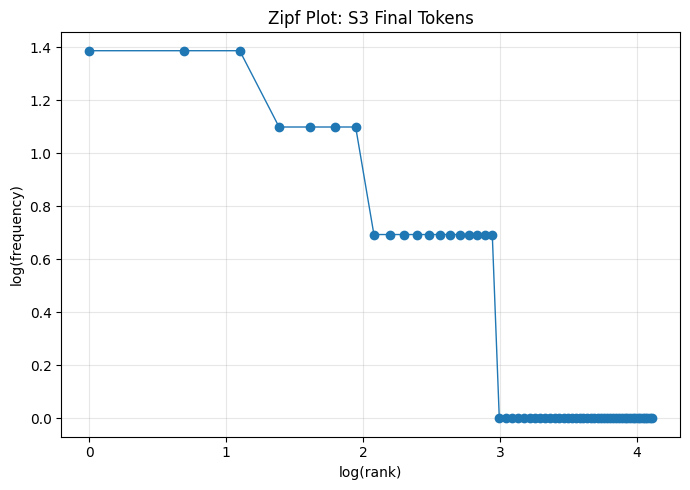

Top 5 bigrams in S1:


,Bigram,Frequency
0,. i,6
1,. the,5
2,yesterday .,4
3,the printer,3
4,is running,3


Top 5 bigrams in S3:


,Bigram,Frequency
0,running slowly,3
1,since yesterday,3
2,unable use,2
3,n't know,2
4,know changed,2


In [9]:
# Q5: corpus statistics, frequencies, Zipf plot and bigrams
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import ngrams

S1 = [token for result in processed.values() for token in result["tokens"]]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for result in processed.values() for token in result["final"]]
S4 = [porter.stem(token) for token in S3]

def corpus_stats(name, tokens):
    return {"Set": name, "Total tokens": len(tokens),
            "Unique tokens": len(set(tokens)),
            "TTR": (len(set(tokens)) / len(tokens)) if tokens else 0}

stats = pd.DataFrame([corpus_stats("S1: all tokens", S1),
                      corpus_stats("S2: without punctuation", S2),
                      corpus_stats("S3: final tokens", S3),
                      corpus_stats("S4: Porter-stemmed S3", S4)])
display(stats)

freq_S1 = Counter(S1)
freq_S3 = Counter(S3)
print("Top 10 words in S1:")
display(pd.DataFrame(freq_S1.most_common(10), columns=["Word", "Frequency"]))
print("Top 10 words in S3:")
display(pd.DataFrame(freq_S3.most_common(10), columns=["Word", "Frequency"]))

ranked = freq_S3.most_common()
ranks = list(range(1, len(ranked) + 1))
frequencies = [freq for _, freq in ranked]
plt.figure(figsize=(7, 5))
plt.plot([math.log(r) for r in ranks], [math.log(f) for f in frequencies], marker="o", linewidth=1)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf Plot: S3 Final Tokens")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

def top_bigrams(tokens, n=5):
    return Counter(ngrams(tokens, 2)).most_common(n)

print("Top 5 bigrams in S1:")
display(pd.DataFrame([{"Bigram": " ".join(bg), "Frequency": count} for bg, count in top_bigrams(S1)]))
print("Top 5 bigrams in S3:")
display(pd.DataFrame([{"Bigram": " ".join(bg), "Frequency": count} for bg, count in top_bigrams(S3)]))


**Your answer:** TTR is the number of unique tokens divided by the total number of tokens. It can change from S1 to S4 because S1 includes punctuation and stopwords, while S3 removes them, and S4 additionally merges related word forms through Porter stemming. Removing frequent stopwords may increase TTR, while stemming usually reduces the number of unique forms and can lower TTR. The direction and size of the change depend on the generated tickets; use the displayed table for the actual values.
